# 线性回归的从零开始实现
:label:`sec_linear_scratch`

在了解线性回归的关键思想之后，我们可以开始通过代码来动手实现线性回归了。
在这一节中，(**我们将从零开始实现整个方法，
包括数据流水线、模型、损失函数和小批量随机梯度下降优化器**)。
虽然现代的深度学习框架几乎可以自动化地进行所有这些工作，但从零开始实现可以确保我们真正知道自己在做什么。
同时，了解更细致的工作原理将方便我们自定义模型、自定义层或自定义损失函数。
在这一节中，我们将只使用张量和自动求导。
在之后的章节中，我们会充分利用深度学习框架的优势，介绍更简洁的实现方式。


In [1]:
%matplotlib inline
import random
import torch
from d2l import torch as d2l

## 生成数据集

为了简单起见，我们将[**根据带有噪声的线性模型构造一个人造数据集。**]
我们的任务是使用这个有限样本的数据集来恢复这个模型的参数。
我们将使用低维数据，这样可以很容易地将其可视化。
在下面的代码中，我们生成一个包含1000个样本的数据集，
每个样本包含从标准正态分布中采样的2个特征。
我们的合成数据集是一个矩阵$\mathbf{X}\in \mathbb{R}^{1000 \times 2}$。

(**我们使用线性模型参数$\mathbf{w} = [2, -3.4]^\top$、$b = 4.2$
和噪声项$\epsilon$生成数据集及其标签：

$$\mathbf{y}= \mathbf{X} \mathbf{w} + b + \mathbf\epsilon.$$
**)

$\epsilon$可以视为模型预测和标签时的潜在观测误差。
在这里我们认为标准假设成立，即$\epsilon$服从均值为0的正态分布。
为了简化问题，我们将标准差设为0.01。
下面的代码生成合成数据集。


In [2]:
def synthetic_data(w, b, num_examples):  #@save
    """生成y=Xw+b+噪声"""
    X = torch.normal(0, 1, (num_examples, len(w)))
    y = torch.matmul(X, w) + b
    y += torch.normal(0, 0.01, y.shape)
    return X, y.reshape((-1, 1))

In [3]:
true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = synthetic_data(true_w, true_b, 1000)

注意，[**`features`中的每一行都包含一个二维数据样本，
`labels`中的每一行都包含一维标签值（一个标量）**]。


In [4]:
print('features:', features[0],'\nlabel:', labels[0])

features: tensor([-0.8375,  1.2787]) 
label: tensor([-1.8299])


通过生成第二个特征`features[:, 1]`和`labels`的散点图，
可以直观观察到两者之间的线性关系。


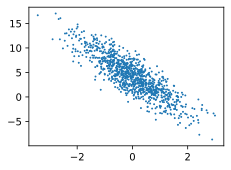

In [5]:
d2l.set_figsize()
d2l.plt.scatter(features[:, (1)].detach().numpy(), labels.detach().numpy(), 1);

## 读取数据集

回想一下，训练模型时要对数据集进行遍历，每次抽取一小批量样本，并使用它们来更新我们的模型。
由于这个过程是训练机器学习算法的基础，所以有必要定义一个函数，
该函数能打乱数据集中的样本并以小批量方式获取数据。

在下面的代码中，我们[**定义一个`data_iter`函数，
该函数接收批量大小、特征矩阵和标签向量作为输入，生成大小为`batch_size`的小批量**]。
每个小批量包含一组特征和标签。


In [1]:
def data_iter(batch_size, features, labels):  # 定义函数：批量大小、特征、标签
    num_examples = len(features)
    indices = list(range(num_examples)) # 生成索引列表 [0,1,2,...,999]
    # 这些样本是随机读取的，没有特定的顺序
    random.shuffle(indices)
    for i in range(0, num_examples, batch_size):  # 打乱顺序
        batch_indices = torch.tensor(
            indices[i: min(i + batch_size, num_examples)])
        yield features[batch_indices], labels[batch_indices]

通常，我们利用GPU并行运算的优势，处理合理大小的“小批量”。
每个样本都可以并行地进行模型计算，且每个样本损失函数的梯度也可以被并行计算。
GPU可以在处理几百个样本时，所花费的时间不比处理一个样本时多太多。

我们直观感受一下小批量运算：读取第一个小批量数据样本并打印。
每个批量的特征维度显示批量大小和输入特征数。
同样的，批量的标签形状与`batch_size`相等。


In [7]:
batch_size = 10

for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break

tensor([[-0.5695, -0.4936],
        [-0.0521, -0.1976],
        [ 0.3299,  1.0874],
        [-1.3880, -0.7413],
        [-0.5341,  1.9649],
        [ 1.9274, -1.9851],
        [-0.3771, -0.8287],
        [-0.9247, -0.3443],
        [-1.6365, -0.8367],
        [-1.8147, -0.1402]]) 
 tensor([[ 4.7427],
        [ 4.7724],
        [ 1.1812],
        [ 3.9341],
        [-3.5548],
        [14.8060],
        [ 6.2663],
        [ 3.5214],
        [ 3.7761],
        [ 1.0575]])


当我们运行迭代时，我们会连续地获得不同的小批量，直至遍历完整个数据集。
上面实现的迭代对教学来说很好，但它的执行效率很低，可能会在实际问题上陷入麻烦。
例如，它要求我们将所有数据加载到内存中，并执行大量的随机内存访问。
在深度学习框架中实现的内置迭代器效率要高得多，
它可以处理存储在文件中的数据和数据流提供的数据。

## 初始化模型参数

[**在我们开始用小批量随机梯度下降优化我们的模型参数之前**]，
(**我们需要先有一些参数**)。
在下面的代码中，我们通过从均值为0、标准差为0.01的正态分布中采样随机数来初始化权重，
并将偏置初始化为0。


In [8]:
w = torch.normal(0, 0.01, size=(2,1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

在初始化参数之后，我们的任务是更新这些参数，直到这些参数足够拟合我们的数据。
每次更新都需要计算损失函数关于模型参数的梯度。
有了这个梯度，我们就可以向减小损失的方向更新每个参数。
因为手动计算梯度很枯燥而且容易出错，所以没有人会手动计算梯度。
我们使用 :numref:`sec_autograd`中引入的自动微分来计算梯度。

## 定义模型

接下来，我们必须[**定义模型，将模型的输入和参数同模型的输出关联起来。**]
回想一下，要计算线性模型的输出，
我们只需计算输入特征$\mathbf{X}$和模型权重$\mathbf{w}$的矩阵-向量乘法后加上偏置$b$。
注意，上面的$\mathbf{Xw}$是一个向量，而$b$是一个标量。
回想一下 :numref:`subsec_broadcasting`中描述的广播机制：
当我们用一个向量加一个标量时，标量会被加到向量的每个分量上。


In [9]:
def linreg(X, w, b):  #@save
    """线性回归模型"""
    return torch.matmul(X, w) + b #torch.matmul矩阵乘法

## [**定义损失函数**]

因为需要计算损失函数的梯度，所以我们应该先定义损失函数。
这里我们使用 :numref:`sec_linear_regression`中描述的平方损失函数。
在实现中，我们需要将真实值`y`的形状转换为和预测值`y_hat`的形状相同。


In [10]:
def squared_loss(y_hat, y):  #@save  # 定义函数：y_hat是预测值，y是真实标签
    """均方损失"""
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2

## (**定义优化算法**)

正如我们在 :numref:`sec_linear_regression`中讨论的，线性回归有解析解。
尽管线性回归有解析解，但本书中的其他模型却没有。
这里我们介绍小批量随机梯度下降。

在每一步中，使用从数据集中随机抽取的一个小批量，然后根据参数计算损失的梯度。
接下来，朝着减少损失的方向更新我们的参数。
下面的函数实现小批量随机梯度下降更新。
该函数接受模型参数集合、学习速率和批量大小作为输入。每
一步更新的大小由学习速率`lr`决定。
因为我们计算的损失是一个批量样本的总和，所以我们用批量大小（`batch_size`）
来规范化步长，这样步长大小就不会取决于我们对批量大小的选择。


In [11]:
def sgd(params, lr, batch_size):  #@save # 定义函数：参数列表、学习率、批量大小
    """小批量随机梯度下降"""
    with torch.no_grad(): # 更新参数时不需要记录梯度，省内存
        for param in params: # 遍历每个参数（w 和 b）
            param -= lr * param.grad / batch_size  # 沿梯度反方向走一小步
            param.grad.zero_() # 清空梯度，防止累加

## 训练

现在我们已经准备好了模型训练所有需要的要素，可以实现主要的[**训练过程**]部分了。
理解这段代码至关重要，因为从事深度学习后，
相同的训练过程几乎一遍又一遍地出现。
在每次迭代中，我们读取一小批量训练样本，并通过我们的模型来获得一组预测。
计算完损失后，我们开始反向传播，存储每个参数的梯度。
最后，我们调用优化算法`sgd`来更新模型参数。

概括一下，我们将执行以下循环：

* 初始化参数
* 重复以下训练，直到完成
    * 计算梯度$\mathbf{g} \leftarrow \partial_{(\mathbf{w},b)} \frac{1}{|\mathcal{B}|} \sum_{i \in \mathcal{B}} l(\mathbf{x}^{(i)}, y^{(i)}, \mathbf{w}, b)$
    * 更新参数$(\mathbf{w}, b) \leftarrow (\mathbf{w}, b) - \eta \mathbf{g}$

在每个*迭代周期*（epoch）中，我们使用`data_iter`函数遍历整个数据集，
并将训练数据集中所有样本都使用一次（假设样本数能够被批量大小整除）。
这里的迭代周期个数`num_epochs`和学习率`lr`都是超参数，分别设为3和0.03。
设置超参数很棘手，需要通过反复试验进行调整。
我们现在忽略这些细节，以后会在 :numref:`chap_optimization`中详细介绍。


In [12]:
lr = 0.03 # 学习率：每次改参数迈多大步
num_epochs = 3 # 训练轮数：把全部数据刷3遍
net = linreg
loss = squared_loss

In [13]:
for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)  # X和y的小批量损失
        # 因为l形状是(batch_size,1)，而不是一个标量。l中的所有元素被加到一起，
        # 并以此计算关于[w,b]的梯度
        l.sum().backward()
        sgd([w, b], lr, batch_size)  # 使用参数的梯度更新参数
    with torch.no_grad():
        train_l = loss(net(features, w, b), labels)
        print(f'epoch {epoch + 1}, loss {float(train_l.mean()):f}')

epoch 1, loss 0.032905
epoch 2, loss 0.000118
epoch 3, loss 0.000049


因为我们使用的是自己合成的数据集，所以我们知道真正的参数是什么。
因此，我们可以通过[**比较真实参数和通过训练学到的参数来评估训练的成功程度**]。
事实上，真实参数和通过训练学到的参数确实非常接近。


In [14]:
print(f'w的估计误差: {true_w - w.reshape(true_w.shape)}')
print(f'b的估计误差: {true_b - b}')

w的估计误差: tensor([ 0.0002, -0.0009], grad_fn=<SubBackward0>)
b的估计误差: tensor([0.0005], grad_fn=<RsubBackward1>)


注意，我们不应该想当然地认为我们能够完美地求解参数。
在机器学习中，我们通常不太关心恢复真正的参数，而更关心如何高度准确预测参数。
幸运的是，即使是在复杂的优化问题上，随机梯度下降通常也能找到非常好的解。
其中一个原因是，在深度网络中存在许多参数组合能够实现高度精确的预测。

## 小结

* 我们学习了深度网络是如何实现和优化的。在这一过程中只使用张量和自动微分，不需要定义层或复杂的优化器。
* 这一节只触及到了表面知识。在下面的部分中，我们将基于刚刚介绍的概念描述其他模型，并学习如何更简洁地实现其他模型。

## 练习

1. 如果我们将权重初始化为零，会发生什么。算法仍然有效吗？
1. 假设试图为电压和电流的关系建立一个模型。自动微分可以用来学习模型的参数吗?
1. 能基于[普朗克定律](https://en.wikipedia.org/wiki/Planck%27s_law)使用光谱能量密度来确定物体的温度吗？
1. 计算二阶导数时可能会遇到什么问题？这些问题可以如何解决？
1. 为什么在`squared_loss`函数中需要使用`reshape`函数？
1. 尝试使用不同的学习率，观察损失函数值下降的快慢。
1. 如果样本个数不能被批量大小整除，`data_iter`函数的行为会有什么变化？


# **做练习**

In [21]:
#选做几个练习
#练习5
#不用reshape函数的话广播机制会把(10,)当成(1,10)，结果会变成(10,10)，(广播机制从右边向左边对齐)每个样本算了10次,不是逐个样本相减

epoch 1, loss 114141232.000000
epoch 2, loss 260216.421875
epoch 3, loss 591.228516


In [28]:
#练习6
w = torch.normal(0, 0.01, size=(2, 1),requires_grad=True)
b = torch.zeros(1,requires_grad=True)

for epoch in range(3):
    for X,y in data_iter(10, features, labels):
        l = squared_loss(linreg(X, w, b), y)
        l.sum().backward()
        sgd([w, b], 0.001, 10)
    with torch.no_grad():
        train_1 = squared_loss(linreg(features, w, b), labels)
        print(f'lr=0.001, epoch {epoch+1}, loss {float(train_1.mean()):f}') #:f：按小数格式显示（默认 6 位小数）。

lr=0.001, epoch 1, loss 13.890738
lr=0.001, epoch 2, loss 11.308026
lr=0.001, epoch 3, loss 9.206318


In [31]:
w = torch.normal(0, 0.01, size=(2, 1),requires_grad=True)
b = torch.zeros(1,requires_grad=True)

for epoch in range(3):
    for X,y in data_iter(10, features, labels):
        l = squared_loss(linreg(X, w, b), y)
        l.sum().backward()
        sgd([w, b], 1, 10)
    with torch.no_grad():
        train_1 = squared_loss(linreg(features, w, b), labels)
        print(f"lr=1, epoch {epoch+1}, loss {float(train_1.mean()):f}") #:f：按小数格式显示（默认 6 位小数）。 #有 f "→ 花括号里的变量生效。

lr=1, epoch 1, loss 0.000118
lr=1, epoch 2, loss 0.000053
lr=1, epoch 3, loss 0.000129


# Day 10：线性回归从零实现（3.2）

## 一、知识点大白话总结（我的小抄）

昨天学了 3.1 的理论，今天动手把线性回归从零写出来。

### 核心流程（7 步）
1. **生成数据**：`synthetic_data(w, b, 1000)` —— 按标准答案造 1000 条假数据。
2. **读数据**：`data_iter(batch_size, features, labels)` —— 发牌员，每批给 10 条。
3. **初始化参数**：`w`、`b` 都要 `requires_grad=True`，打开求导开关。
4. **定义模型**：`linreg(X, w, b)` = `X @ w + b`。
5. **定义损失**：`squared_loss(y_hat, y)` = `(y_hat - y.reshape(y_hat.shape))**2 / 2`。
6. **定义优化**：`sgd(params, lr, batch_size)` = `param -= lr * param.grad / batch_size`，然后 `zero_()` 清零。
7. **训练循环**：双层 for，每批 `backward()` + `sgd()`，每轮 `no_grad()` 评估。

### 关键概念
- **batch_size**：每批几条，决定更新频率。
- **epoch**：全部数据过一遍。3 个 epoch = 过 3 遍。
- **X vs features**：训练用 `X`（一批），评估用 `features`（全部）。
- **requires_grad=True**：不加就报 `RuntimeError`。

## 二、今天遇到的坑与疑问

1. **拼写错误**：`range` 写成 `rage`，`linreg` 写成 `linger`，报 `NameError`。
2. **f-string 的两个 f**：前面的 `f` 是格式化开关，冒号后的 `:f` 是按小数显示，不是同一个东西。
3. **引号要成对**：开头 `'` 和结尾 `'` 必须配对，少了报 `SyntaxError`。
4. **缩进层级**：每批执行缩进 8 格，每轮执行缩进 4 格，`with no_grad` 里面再 8 格。
5. **`features` vs `X`**：训练用 `X`（一批），评估用 `features`（全部）。
6. **`requires_grad=True`**：忘了加，`backward()` 报 `RuntimeError`。
7. **`squared_loss` 里的 `reshape`**：不 reshape，`(10,)` 会广播成 `(10,10)`，算错。

## 三、今日感想（碎碎念）

今天 3.2 的代码来回改了好多次，缩进、拼写、括号，每个小地方都能卡半天。但慢慢发现，编程不是“凭空想出来”，而是“看懂 → 抄 → 改 → 默写”。今天能对着书把 3.2 跑通，明天试试关书默写。慢就慢吧，至少没跳过。

[Discussions](https://discuss.d2l.ai/t/1778)
